# Lab 02 — Password Analysis
### Detecting a shared default password in a corporate password audit

**Module:** IA for Cybersecurity — 3rd Year, Second Cycle (CyS)
**Use case:** Password analysis
**Tool:** Python (pandas, NumPy, Matplotlib, Seaborn, zxcvbn)

---

**Scenario.** The security team of a mid-sized company runs an *authorized* password audit every quarter:
the password hashes of all Active Directory accounts are exported and run through a cracking tool
(e.g. hashcat) to measure how strong employee passwords really are.

This notebook:

1. Simulates a realistic audit dataset (~1,200 accounts) — no real credentials are used.
2. Injects one anomaly: a **cohort of new accounts all left on the same default password** by the helpdesk.
3. Explores the data (strength, length, composition, per department).
4. Visualizes the anomaly from two independent angles.
5. Defines a simple detection rule that works on **hashes only** (no plaintext needed).
6. Evaluates the rule on anomalous data **and** on a clean, normal-only audit.

> Run top to bottom. Everything is generated locally with fixed random seeds, so the results are reproducible.

## 0. Setup
`zxcvbn` is Dropbox's open-source password-strength estimator (score 0 = very weak … 4 = very strong).
Install it once with `pip install zxcvbn` if it is missing.

In [1]:
import hashlib
import string
from datetime import datetime, timedelta

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from zxcvbn import zxcvbn

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 20)
sns.set_theme(style="whitegrid", context="notebook")

# Colors used consistently in every figure
NORMAL_C = "#0B6E93"   # normal data
ANOMALY_C = "#C0392B"  # injected anomaly
GRID_C = "#9AA5B1"

import os
os.makedirs("figures", exist_ok=True)

## 1. Dataset — simulated password audit

### 1.1 How the data is generated
Each row is one user account, as it would appear after an audit run:

| Column | Meaning |
|---|---|
| `username` | `firstname.lastname` |
| `department` | IT, HR, Finance, Sales, … |
| `account_created` | date the account was created |
| `pwd_last_set` | last time the password was changed (AD attribute `pwdLastSet`) |
| `password` | plaintext **recovered by the cracking tool** (only available in an authorized audit) |
| `pwd_hash` | unsalted hash of the password (SHA-256 here, standing in for the Windows NT hash) |
| `is_injected` | ground-truth label — **hidden from the detection rule**, used only for evaluation |

Normal users choose passwords following habits observed in real breach studies,
and all of them satisfy the company policy (**≥ 8 characters, at least 3 of 4 character classes**):

| Habit | Example | Share |
|---|---|---|
| Word + year (+ symbol) | `Mouloudia2019!` | 38 % |
| Own first name + date | `Karim0312!` | 17 % |
| "Leet" word + digits | `Dr@g0n47` | 14 % |
| Passphrase | `Tiger-Coffee-Blue7` | 13 % |
| Random (password manager) | `q7#Lm…` | 12 % |
| Well-known "compliant" password | `P@ssw0rd123` | 6 % |

Because NT hashes are **not salted**, two accounts with the same password have the same hash.
This property is what the detection rule will use.

In [2]:
FIRST_NAMES = ["amine", "karim", "yacine", "sofiane", "walid", "mehdi", "nassim", "rachid", "farid", "samir",
               "omar", "bilal", "hamza", "anis", "riad", "nour", "yasmine", "amel", "sarah", "lina", "imane",
               "meriem", "sonia", "nadia", "lamia", "khadidja", "rania", "asma", "ines", "salima", "hichem",
               "fares", "adel", "malik", "zakaria", "selma", "dounia", "houda", "wafa", "amira"]
LAST_NAMES = ["benali", "bouzid", "haddad", "mansouri", "belkacem", "brahimi", "cherif", "djebbar", "ferhat",
              "ghezali", "hamidi", "kaci", "larbi", "meziane", "rahmani", "saidi", "taleb", "ziani", "bensaid",
              "boudiaf", "chaouch", "derradji", "khelifi", "lounis", "messaoudi", "ouali", "saadi", "touati",
              "yahiaoui", "zerrouki", "amrani", "bakir", "benyahia", "guerfi", "hadjadj", "kerroum"]
DEPARTMENTS = ["IT", "HR", "Finance", "Sales", "Operations", "Legal", "Marketing", "R&D"]
DEPT_WEIGHTS = [0.12, 0.07, 0.11, 0.22, 0.20, 0.05, 0.10, 0.13]

WORDS = ["soleil", "football", "oran", "algerie", "mouloudia", "chocolat", "dragon", "princess", "monkey",
         "shadow", "jasmine", "sunshine", "tigre", "liberte", "bahia", "marina", "summer", "winter",
         "barcelona", "realmadrid", "bonjour", "famille", "maison", "ronaldo", "messi", "galaxy", "falcon"]
PASSPHRASE_WORDS = ["tiger", "coffee", "blue", "river", "orange", "desert", "pencil", "window", "silver",
                    "garden", "rocket", "violin", "camel", "cloud", "harbor", "lemon", "sahara", "marble"]
# Passwords that look "complex" and pass the policy but appear in every cracking wordlist
COMMON_COMPLIANT = ["Password1!", "P@ssw0rd", "P@ssw0rd123", "Azerty123!", "Qwerty123!", "Welcome1!",
                    "Algerie2024!", "Admin@123", "Abc12345!", "Soleil2025!", "Oran2025!", "Football1!",
                    "Summer2025!", "Winter2025!", "Iloveyou1!", "Changeme1!", "Bonjour123!",
                    "Motdepasse1!", "Company@2025", "Azerty@2024"]
LEET = str.maketrans({"a": "@", "e": "3", "o": "0", "i": "1", "s": "$"})
SYMBOLS = "!@#.*"


def make_password(rng, first_name):
    # Draw one policy-compliant password following a realistic human habit.
    habit = rng.choice(["word_year", "name_date", "leet", "passphrase", "random", "common"],
                       p=[0.38, 0.17, 0.14, 0.13, 0.12, 0.06])
    if habit == "word_year":
        pw = rng.choice(WORDS).capitalize() + str(rng.integers(1975, 2027))
        if rng.random() < 0.6:
            pw += rng.choice(list(SYMBOLS))
    elif habit == "name_date":
        pw = first_name.capitalize() + f"{rng.integers(1, 29):02d}{rng.integers(1, 13):02d}" + rng.choice(list(SYMBOLS))
    elif habit == "leet":
        pw = rng.choice(WORDS).translate(LEET).capitalize() + f"{rng.integers(0, 100):02d}"
    elif habit == "passphrase":
        words = rng.choice(PASSPHRASE_WORDS, size=int(rng.integers(3, 5)), replace=False)
        pw = "-".join(w.capitalize() for w in words) + str(rng.integers(0, 10))
    elif habit == "random":
        alphabet = string.ascii_letters + string.digits + "!@#$%^&*?"
        pw = "".join(rng.choice(list(alphabet), size=int(rng.integers(12, 17))))
        pw += rng.choice(list("0123456789"))  # guarantees >= 3 classes
    else:
        pw = rng.choice(COMMON_COMPLIANT)
    pw = str(pw)
    while len(pw) < 8:              # the policy rejects anything shorter, so users pad with digits
        pw += str(rng.integers(0, 10))
    return pw


def hash_pw(pw):
    # Unsalted hash (stand-in for the Windows NT hash). Same password -> same hash.
    return hashlib.sha256(pw.encode()).hexdigest()

In [3]:
def generate_audit(n_users, seed, audit_date, inject=False, n_injected=40, cohort_date=None,
                   default_password="Welcome@2026"):
    # Simulate one password-audit export. If inject=True, add the anomaly (see section 1.2).
    rng = np.random.default_rng(seed)
    rows, used = [], set()

    def new_username(first, last):
        u, k = f"{first}.{last}", 2
        while u in used:
            u, k = f"{first}.{last}{k}", k + 1
        used.add(u)
        return u

    for _ in range(n_users):
        first, last = rng.choice(FIRST_NAMES), rng.choice(LAST_NAMES)
        created = audit_date - timedelta(days=int(rng.integers(60, 8 * 365)))
        # 90-day rotation policy: most users changed their password recently, a few are stale
        if rng.random() < 0.9:
            age = int(rng.integers(0, 120))
        else:
            age = int(rng.integers(120, 700))
        pwd_last_set = max(created, audit_date - timedelta(days=age)) + timedelta(
            hours=int(rng.integers(8, 18)), minutes=int(rng.integers(0, 60)))
        pw = make_password(rng, first)
        rows.append((new_username(first, last), rng.choice(DEPARTMENTS, p=DEPT_WEIGHTS),
                     created, pwd_last_set, pw, False))

    if inject:
        # ---- THE ANOMALY ------------------------------------------------------------
        # A batch of new hires is onboarded on the same morning. The helpdesk creates all
        # accounts with one default password and forgets "User must change password at
        # next logon". Six weeks later, nobody has changed it.
        for i in range(n_injected):
            first, last = rng.choice(FIRST_NAMES), rng.choice(LAST_NAMES)
            t = cohort_date + timedelta(hours=9, minutes=int(i * 1.5))   # created in one burst
            rows.append((new_username(first, last), rng.choice(DEPARTMENTS, p=DEPT_WEIGHTS),
                         t, t, default_password, True))

    df = pd.DataFrame(rows, columns=["username", "department", "account_created",
                                     "pwd_last_set", "password", "is_injected"])
    df["pwd_hash"] = df["password"].map(hash_pw)
    return df.sample(frac=1, random_state=seed).reset_index(drop=True)   # shuffle rows

### 1.2 Three audit exports

| Dataset | Purpose | Anomaly? |
|---|---|---|
| `baseline` — audit of April 2026 | Learn what "normal" password sharing looks like and **calibrate** the rule threshold | No |
| `current` — audit of 15 October 2026 | The audit under investigation | **Yes — 40 accounts** created on 1 Sept 2026 with `Welcome@2026` |
| `clean` — independent normal audit | Measure **false positives on purely normal data** | No |

Using a separate dataset to set the threshold avoids tuning the rule on the very data we evaluate it on.

In [4]:
AUDIT_DATE   = datetime(2026, 10, 15)
COHORT_DATE  = datetime(2026, 9, 1)
DEFAULT_PW   = "Welcome@2026"

baseline = generate_audit(1150, seed=7,    audit_date=datetime(2026, 4, 15))
current  = generate_audit(1200, seed=42,   audit_date=AUDIT_DATE, inject=True,
                          n_injected=40, cohort_date=COHORT_DATE, default_password=DEFAULT_PW)
clean    = generate_audit(1200, seed=2026, audit_date=AUDIT_DATE)

for name, d in [("baseline", baseline), ("current", current), ("clean", clean)]:
    print(f"{name:9s}: {len(d):5d} accounts | injected anomalies: {d['is_injected'].sum()}")

current.drop(columns="pwd_hash").head(8)

baseline :  1150 accounts | injected anomalies: 0
current  :  1240 accounts | injected anomalies: 40
clean    :  1200 accounts | injected anomalies: 0


,username,department,account_created,pwd_last_set,password,is_injected
0,nadia.ziani,R&D,2025-04-30,2026-07-31 14:51:00,Nadia2110.,False
1,asma.haddad,IT,2022-07-30,2026-07-20 08:43:00,Falcon2019,False
2,rachid.haddad2,Marketing,2020-10-14,2026-09-17 17:32:00,Chocolat2006,False
3,lamia.belkacem,Sales,2023-01-24,2026-06-21 08:19:00,Shadow1986,False
4,samir.ghezali,IT,2025-07-25,2026-09-10 11:52:00,*R*z^PfDj%vp5,False
5,fares.rahmani,Marketing,2022-03-12,2026-08-20 08:26:00,F@lc0n03,False
6,anis.lounis2,Finance,2022-10-30,2026-09-02 10:31:00,B0nj0ur66,False
7,rania.rahmani,Sales,2019-04-16,2026-09-14 09:15:00,M0nk3y33,False


## 2. Feature extraction

For every cracked password we compute:

* **length** and the four **character classes** (upper, lower, digit, symbol);
* **policy compliance** (≥ 8 chars and ≥ 3 classes);
* **zxcvbn score** (0–4) and the estimated **offline crack time** against a fast hash (10¹⁰ guesses/s — realistic for NT hashes on a GPU);
* simple **pattern flags**: contains a year, contains the user's own first name;
* **`share_count`** — how many accounts in the audit have the same hash. This one needs no plaintext at all.

In [5]:
def add_features(df):
    df = df.copy()
    pw = df["password"]
    df["length"]     = pw.str.len()
    df["has_upper"]  = pw.str.contains(r"[A-Z]")
    df["has_lower"]  = pw.str.contains(r"[a-z]")
    df["has_digit"]  = pw.str.contains(r"\d")
    df["has_symbol"] = pw.str.contains(r"[^A-Za-z0-9]")
    df["n_classes"]  = df[["has_upper", "has_lower", "has_digit", "has_symbol"]].sum(axis=1)
    df["policy_ok"]  = (df["length"] >= 8) & (df["n_classes"] >= 3)
    df["has_year"]   = pw.str.contains(r"(?:19|20)\d{2}")
    first = df["username"].str.split(".").str[0]
    df["has_own_name"] = [f in p.lower() for f, p in zip(first, pw)]

    scores, crack = [], []
    for p, f in zip(pw, first):
        r = zxcvbn(p, user_inputs=[f, "company"])
        scores.append(r["score"])
        crack.append(float(r["crack_times_seconds"]["offline_fast_hashing_1e10_per_second"]))
    df["zxcvbn_score"] = scores
    df["crack_seconds"] = crack

    df["share_count"] = df.groupby("pwd_hash")["pwd_hash"].transform("size")
    df["pwd_age_days"] = (AUDIT_DATE - df["pwd_last_set"]).dt.days
    return df

baseline = add_features(baseline)
current  = add_features(current)
clean    = add_features(clean)
current[["username", "department", "length", "n_classes", "policy_ok",
         "zxcvbn_score", "crack_seconds", "share_count"]].head(8)

,username,department,length,n_classes,policy_ok,zxcvbn_score,crack_seconds,share_count
0,nadia.ziani,R&D,10,4,True,2,0.001001,1
1,asma.haddad,IT,10,3,True,1,0.000003,1
2,rachid.haddad2,Marketing,12,3,True,1,0.000016,1
3,lamia.belkacem,Sales,10,3,True,1,0.000002,1
4,samir.ghezali,IT,13,4,True,4,1000.000000,1
5,fares.rahmani,Marketing,8,4,True,1,0.000019,1
6,anis.lounis2,Finance,9,3,True,1,0.000061,1
7,rania.rahmani,Sales,8,3,True,1,0.000002,1


## 3. Exploratory analysis — what do "normal" passwords look like?

In [6]:
print(f"Accounts audited                    : {len(current)}")
print(f"Policy-compliant passwords          : {current['policy_ok'].mean():.1%}")
print(f"zxcvbn score <= 2 (weak)            : {(current['zxcvbn_score'] <= 2).mean():.1%}")
print(f"Cracked in < 1 second (offline GPU) : {(current['crack_seconds'] < 1).mean():.1%}")
print(f"Contain a year                      : {current['has_year'].mean():.1%}")
print(f"Contain the user's own first name   : {current['has_own_name'].mean():.1%}")
print(f"Median length                       : {current['length'].median():.0f} characters")

Accounts audited                    : 1240
Policy-compliant passwords          : 100.0%
zxcvbn score <= 2 (weak)            : 60.6%
Cracked in < 1 second (offline GPU) : 73.0%
Contain a year                      : 43.5%
Contain the user's own first name   : 17.4%
Median length                       : 11 characters


**Visualization 1 — length and strength.**
Every password passes the complexity policy, yet a large share of them would fall in under a second to an offline attack.
Complexity rules alone give a false sense of security.

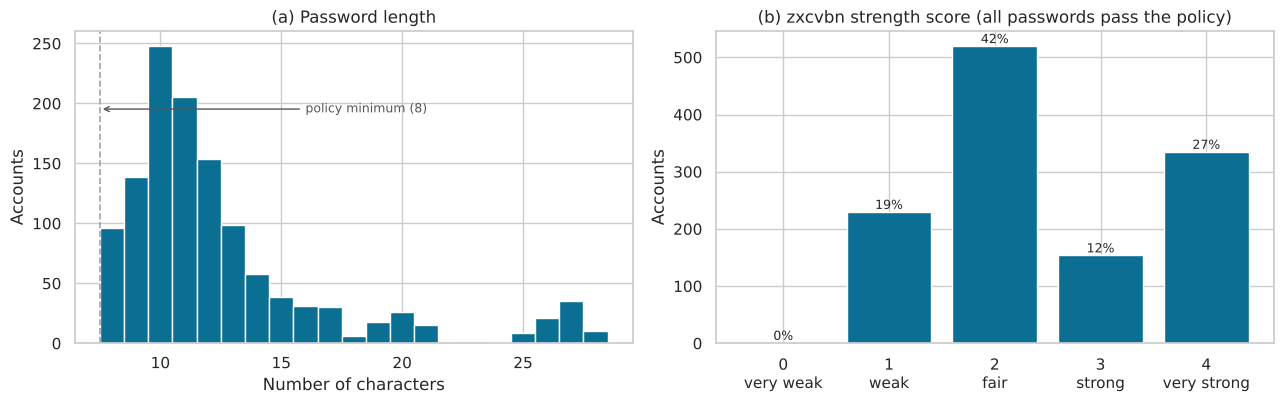

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))

# (a) length distribution
ax = axes[0]
bins = np.arange(current["length"].min() - 0.5, current["length"].max() + 1.5, 1)
ax.hist(current["length"], bins=bins, color=NORMAL_C, edgecolor="white")
ax.axvline(7.5, color=GRID_C, ls="--", lw=1.2)
ax.annotate("policy minimum (8)", xy=(7.5, ax.get_ylim()[1] * 0.75), xytext=(16, ax.get_ylim()[1] * 0.75),
            arrowprops=dict(arrowstyle="->", color="#555"), color="#555", fontsize=9, va="center")
ax.set_title("(a) Password length")
ax.set_xlabel("Number of characters"); ax.set_ylabel("Accounts")

# (b) zxcvbn score distribution
ax = axes[1]
score_counts = current["zxcvbn_score"].value_counts().reindex(range(5), fill_value=0)
labels = ["0\nvery weak", "1\nweak", "2\nfair", "3\nstrong", "4\nvery strong"]
bars = ax.bar(labels, score_counts.values, color=NORMAL_C)
for b, v in zip(bars, score_counts.values):
    ax.text(b.get_x() + b.get_width() / 2, v + 5, f"{v / len(current):.0%}", ha="center", fontsize=9)
ax.set_title("(b) zxcvbn strength score (all passwords pass the policy)")
ax.set_ylabel("Accounts")

plt.tight_layout()
plt.savefig("figures/fig1_length_strength.png", dpi=150, bbox_inches="tight")
plt.show()

**Visualization 2 — strength by department.**
Each row sums to 100 %. This shows where awareness training would help most.

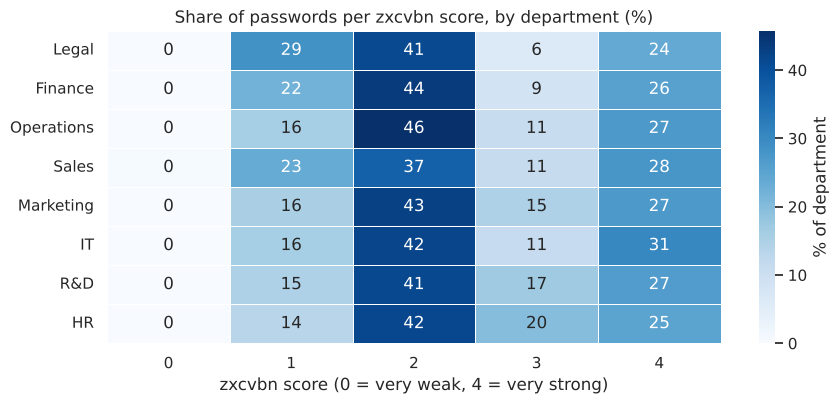

In [8]:
heat = (pd.crosstab(current["department"], current["zxcvbn_score"], normalize="index") * 100)
heat = heat.reindex(columns=range(5), fill_value=0)
heat = heat.loc[heat[[0, 1, 2]].sum(axis=1).sort_values(ascending=False).index]   # weakest first

plt.figure(figsize=(9, 4.2))
sns.heatmap(heat, annot=True, fmt=".0f", cmap="Blues", cbar_kws={"label": "% of department"},
            linewidths=0.5, linecolor="white")
plt.title("Share of passwords per zxcvbn score, by department (%)")
plt.xlabel("zxcvbn score (0 = very weak, 4 = very strong)")
plt.ylabel("")
plt.tight_layout()
plt.savefig("figures/fig2_strength_by_department.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Looking for the anomaly

Two questions an auditor asks next:

1. **Are passwords shared between accounts?** In a normal population a few users independently pick the same
   famous password (`P@ssw0rd123`…), so small clusters of 2–8 accounts are expected. A large cluster is not.
2. **When were passwords set?** With a 90-day rotation policy, password changes are spread evenly over time.
   A burst of password-set events on a single day points to bulk account creation.

**Visualization 3 — the most shared password hashes.**
Only hashes are displayed (first 10 hex characters) — an analyst does not need to see the plaintext to spot reuse.

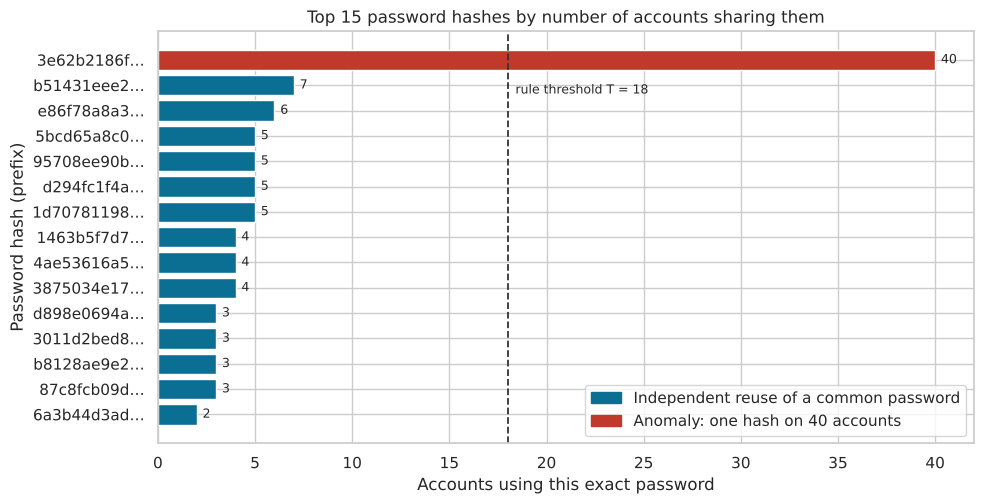

In [9]:
# Threshold of the detection rule — explained and calibrated in section 5
baseline_max = baseline.groupby("pwd_hash").size().max()
THRESHOLD = max(10, 2 * baseline_max)

top = (current.groupby("pwd_hash")
       .agg(accounts=("username", "size"), injected=("is_injected", "any"))
       .sort_values("accounts", ascending=False).head(15))

fig, ax = plt.subplots(figsize=(10, 5.2))
colors = [ANOMALY_C if inj else NORMAL_C for inj in top["injected"]]
ax.barh([h[:10] + "…" for h in top.index], top["accounts"], color=colors)
ax.invert_yaxis()
ax.axvline(THRESHOLD, color="#333", ls="--", lw=1.3)
ax.text(THRESHOLD + 0.4, 1.2, f"rule threshold T = {THRESHOLD}", va="center", fontsize=9)
for i, v in enumerate(top["accounts"]):
    ax.text(v + 0.3, i, str(v), va="center", fontsize=9)
ax.set_title("Top 15 password hashes by number of accounts sharing them")
ax.set_xlabel("Accounts using this exact password")
ax.set_ylabel("Password hash (prefix)")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=NORMAL_C, label="Independent reuse of a common password"),
                   Patch(color=ANOMALY_C, label="Anomaly: one hash on 40 accounts")],
          loc="lower right")
plt.tight_layout()
plt.savefig("figures/fig3_top_shared_hashes.png", dpi=150, bbox_inches="tight")
plt.show()

**Visualization 4 — when were passwords last set?**

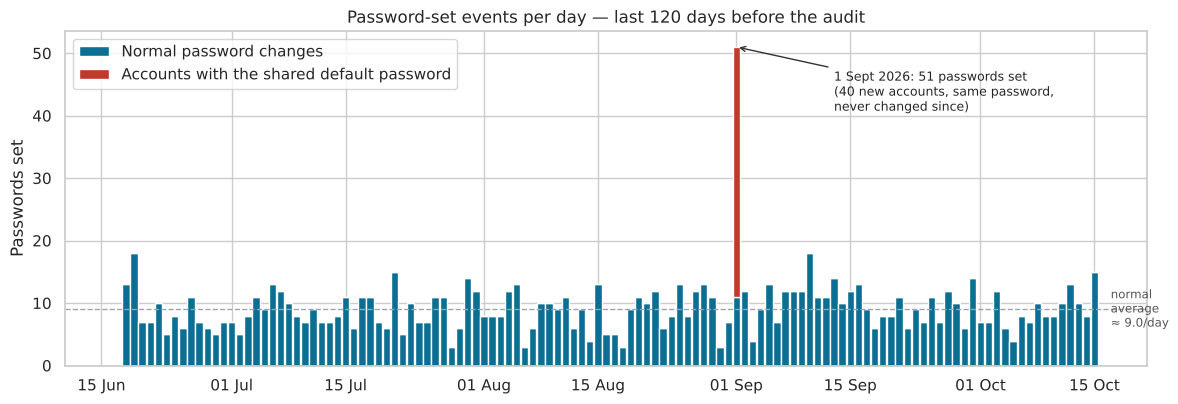

In [10]:
window_start = AUDIT_DATE - timedelta(days=120)
recent = current[current["pwd_last_set"] >= window_start].copy()
recent["day"] = recent["pwd_last_set"].dt.floor("D")
days = pd.date_range(window_start, AUDIT_DATE, freq="D")
normal_daily = recent[~recent["is_injected"]].groupby("day").size().reindex(days, fill_value=0)
anom_daily   = recent[recent["is_injected"]].groupby("day").size().reindex(days, fill_value=0)

fig, ax = plt.subplots(figsize=(12, 4.2))
ax.bar(days, normal_daily.values, width=0.9, color=NORMAL_C, label="Normal password changes")
ax.bar(days, anom_daily.values, width=0.9, bottom=normal_daily.values, color=ANOMALY_C,
       label="Accounts with the shared default password")
peak = (normal_daily + anom_daily)[COHORT_DATE]
ax.annotate(f"1 Sept 2026: {peak} passwords set\n(40 new accounts, same password,\nnever changed since)",
            xy=(COHORT_DATE, peak), xytext=(COHORT_DATE + timedelta(days=12), peak * 0.8),
            arrowprops=dict(arrowstyle="->", color="#333"), fontsize=9)
ax.axhline(normal_daily.mean(), color=GRID_C, ls="--", lw=1)
ax.text(days[-1] + timedelta(days=2), normal_daily.mean(), f"normal\naverage\n≈ {normal_daily.mean():.1f}/day",
        fontsize=8.5, color="#555", va="center")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
ax.set_title("Password-set events per day — last 120 days before the audit")
ax.set_ylabel("Passwords set"); ax.legend(loc="upper left")
plt.tight_layout()
plt.savefig("figures/fig4_pwd_set_timeline.png", dpi=150, bbox_inches="tight")
plt.show()

In [11]:
# What exactly is in the big cluster? (an auditor would now look at the cracked plaintext)
big = current[current["share_count"] >= THRESHOLD]
print("Plaintext of the flagged hash :", list(big["password"].unique()))
print("Passes the complexity policy  :", big["policy_ok"].all())
print("zxcvbn score                  :", big["zxcvbn_score"].unique())
print("Offline crack time            : %.4f s" % big["crack_seconds"].iloc[0])
print("Accounts created between      :", big["account_created"].min(), "and", big["account_created"].max())
print("Password ever changed?        :", (big["pwd_last_set"] > big["account_created"]).any())
print("\nDepartments affected:")
print(big["department"].value_counts().to_string())

Plaintext of the flagged hash : ['Welcome@2026']
Passes the complexity policy  : True
zxcvbn score                  : [2]
Offline crack time            : 0.0045 s
Accounts created between      : 2026-09-01 09:00:00 and 2026-09-01 09:58:00
Password ever changed?        : False

Departments affected:
department
Sales         9
Finance       7
R&D           7
Operations    7
Marketing     5
HR            3
Legal         1
IT            1


## 5. Detection rule

> **Rule — "mass password reuse":**
> flag every account whose password hash is shared by **T or more** accounts in the same audit.

```sql
-- SIEM / SQL version
SELECT username FROM audit
WHERE pwd_hash IN (SELECT pwd_hash FROM audit GROUP BY pwd_hash HAVING COUNT(*) >= :T);
```

**Why it works without cracking anything:** NT hashes are unsalted, so identical passwords give identical hashes.
The rule can run on the raw hash export, before any plaintext is recovered.

**Choosing T.** Some sharing is normal (people independently choose `P@ssw0rd123`).
We measure the largest normal cluster on the *baseline* audit and set `T = max(10, 2 × that value)`,
so the rule ignores ordinary coincidences but fires on any deliberate or administrative reuse.

In [12]:
print("Baseline audit — size of the 5 biggest normal clusters:",
      baseline.groupby("pwd_hash").size().sort_values(ascending=False).head(5).tolist())
print(f"Largest normal cluster in baseline = {baseline_max}  ->  threshold T = {THRESHOLD}")


def mass_reuse_rule(df, threshold):
    # Returns True for every account whose password hash is used by >= threshold accounts.
    # Uses only the pwd_hash column: no plaintext, no ground-truth label.
    return df.groupby("pwd_hash")["pwd_hash"].transform("size") >= threshold


current["flagged"] = mass_reuse_rule(current, THRESHOLD)
clean["flagged"]   = mass_reuse_rule(clean, THRESHOLD)
print(f"\nCurrent audit: {current['flagged'].sum()} accounts flagged")
print(f"Clean audit  : {clean['flagged'].sum()} accounts flagged")

Baseline audit — size of the 5 biggest normal clusters: [9, 8, 7, 6, 6]
Largest normal cluster in baseline = 9  ->  threshold T = 18

Current audit: 40 accounts flagged
Clean audit  : 0 accounts flagged


## 6. Evaluation on anomalous and normal data

We compare the rule's output to the ground truth (`is_injected`) at **account level**:

* **TP** — injected account flagged · **FN** — injected account missed
* **FP** — normal account flagged · **TN** — normal account not flagged

In [13]:
def evaluate(df, name):
    y, p = df["is_injected"], df["flagged"]
    tp, fp = int((y & p).sum()), int((~y & p).sum())
    fn, tn = int((y & ~p).sum()), int((~y & ~p).sum())
    precision = tp / (tp + fp) if tp + fp else float("nan")
    recall    = tp / (tp + fn) if tp + fn else float("nan")
    fpr       = fp / (fp + tn)
    return dict(dataset=name, accounts=len(df), anomalies=int(y.sum()), TP=tp, FP=fp, FN=fn, TN=tn,
                precision=precision, recall=recall, false_positive_rate=fpr)

results = pd.DataFrame([evaluate(current, "current (with anomaly)"),
                        evaluate(clean,   "clean (normal only)")]).set_index("dataset")
results.round(3)

,accounts,anomalies,TP,FP,FN,TN,precision,recall,false_positive_rate
dataset,,,,,,,,,
current (with anomaly),1240,40,40,0,0,1200,1.0,1.0,0.0
clean (normal only),1200,0,0,0,0,1200,NaN,NaN,0.0


**Visualization 5 — confusion matrices and threshold sensitivity.**
The right-hand plot sweeps T from 2 to 40 to show how robust the chosen value is.

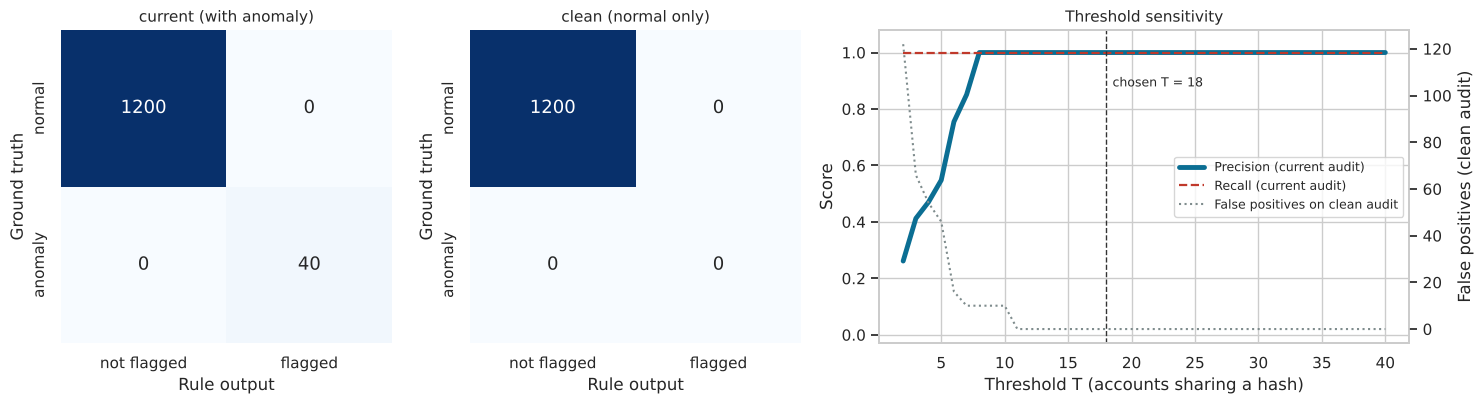

Thresholds giving perfect precision, recall and zero false positives on clean data: T = 11 to 40


In [14]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), gridspec_kw={"width_ratios": [1, 1, 1.6]})

for ax, (name, row) in zip(axes[:2], results.iterrows()):
    cm = np.array([[row.TN, row.FP], [row.FN, row.TP]]).astype(int)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["not flagged", "flagged"], yticklabels=["normal", "anomaly"],
                annot_kws={"size": 13})
    ax.set_title(name, fontsize=11)
    ax.set_xlabel("Rule output"); ax.set_ylabel("Ground truth")

# threshold sweep
ts = np.arange(2, 41)
prec, rec, fp_clean = [], [], []
for t in ts:
    f_cur = mass_reuse_rule(current, t)
    tp = (f_cur & current["is_injected"]).sum(); fp = (f_cur & ~current["is_injected"]).sum()
    prec.append(tp / (tp + fp) if tp + fp else 1.0)
    rec.append(tp / current["is_injected"].sum())
    fp_clean.append(mass_reuse_rule(clean, t).sum())

ax = axes[2]
ax.plot(ts, prec, color=NORMAL_C, lw=3.5, label="Precision (current audit)")
ax.plot(ts, rec, color=ANOMALY_C, lw=1.6, ls="--", label="Recall (current audit)")
ax.set_ylim(-0.03, 1.08); ax.set_xlabel("Threshold T (accounts sharing a hash)"); ax.set_ylabel("Score")
ax2 = ax.twinx()
ax2.plot(ts, fp_clean, color="#7F8C8D", lw=1.5, ls=":", label="False positives on clean audit")
ax2.set_ylabel("False positives (clean audit)"); ax2.grid(False)
ax.axvline(THRESHOLD, color="#333", ls="--", lw=1)
ax.text(THRESHOLD + 0.5, 0.88, f"chosen T = {THRESHOLD}", fontsize=9)
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="center right", fontsize=9)
ax.set_title("Threshold sensitivity", fontsize=11)

plt.tight_layout()
plt.savefig("figures/fig5_evaluation.png", dpi=150, bbox_inches="tight")
plt.show()

safe = [t for t, p, r, f in zip(ts, prec, rec, fp_clean) if p == 1 and r == 1 and f == 0]
print(f"Thresholds giving perfect precision, recall and zero false positives on clean data: "
      f"T = {min(safe)} to {max(safe)}")

## 7. Findings

In [15]:
r_cur, r_cln = results.loc["current (with anomaly)"], results.loc["clean (normal only)"]
weak = (current["zxcvbn_score"] <= 2).mean()
fast = (current["crack_seconds"] < 1).mean()
shared_normal = current[~current["is_injected"] & (current["share_count"] >= 2)]
print(f'''
SUMMARY
-------
Accounts audited                           : {len(current)}
Policy-compliant passwords                 : {current["policy_ok"].mean():.0%}
...of which weak (zxcvbn <= 2)             : {weak:.0%}
...crackable offline in < 1 s              : {fast:.0%}
Normal accounts sharing a password (2..{THRESHOLD - 1}) : {len(shared_normal)}

Anomaly                                    : {DEFAULT_PW!r} on {int(current["is_injected"].sum())} accounts, all created {COHORT_DATE:%d %b %Y}, never changed
Rule                                       : hash shared by >= {THRESHOLD} accounts
Current audit -> precision / recall        : {r_cur.precision:.2f} / {r_cur.recall:.2f}
Clean audit   -> false positives           : {int(r_cln.FP)} of {int(r_cln.accounts)} accounts (FPR = {r_cln.false_positive_rate:.1%})
''')


SUMMARY
-------
Accounts audited                           : 1240
Policy-compliant passwords                 : 100%
...of which weak (zxcvbn <= 2)             : 61%
...crackable offline in < 1 s              : 73%
Normal accounts sharing a password (2..17) : 113

Anomaly                                    : 'Welcome@2026' on 40 accounts, all created 01 Sep 2026, never changed
Rule                                       : hash shared by >= 18 accounts
Current audit -> precision / recall        : 1.00 / 1.00
Clean audit   -> false positives           : 0 of 1200 accounts (FPR = 0.0%)



### Interpretation

1. **The complexity policy is not enough.** Every password satisfies "8 characters, 3 classes", yet most are
   built from predictable patterns (word + year, own first name + date) and are rated weak by zxcvbn.
   The default password `Welcome@2026` itself is fully policy-compliant.
2. **The anomaly is visible from two independent angles:** one hash used by 40 accounts (Fig. 3) and a burst of
   40 password-set events on 1 September 2026 that were never followed by a change (Fig. 4).
   Combined, they point to a bulk onboarding where the helpdesk did not force a password change at first logon.
3. **A one-line rule detects it perfectly** on this data: all 40 accounts are flagged, no normal account is,
   and the clean audit produces no alert. The sweep (Fig. 5) shows a wide safe range of thresholds, so the
   result does not depend on a lucky choice of T.
4. **Small clusters of shared common passwords still exist** below the threshold. They are not the injected
   anomaly but remain a risk (one password-spraying attempt with `P@ssw0rd123` hits all of them).

### Limitations
* The data is simulated; real password habits vary by country, language and company culture.
* The rule relies on **unsalted** hashes (true for Windows NT hashes). With salted hashes (bcrypt, Argon2) identical
  passwords give different hashes, and reuse can only be found after cracking.
* A cohort smaller than T (e.g. 5 accounts) would be missed. Adding a second condition — "≥ 3 accounts sharing a
  hash **and** created within the same hour" — would catch small cohorts while keeping false positives low.

### Recommendations
* Force password change at first logon; generate a unique random initial password per account.
* Block known and company-specific weak passwords (Microsoft Entra Password Protection banned list).
* Run this reuse check automatically after every account-creation batch and in each quarterly audit.